# Session 2 — SciPy, Pandas and a guided data project
### Interpolation, integrals, curve fitting, tables of data, and a small project on real weather data

Read each explanation and **run every cell while you read**. Change the numbers, run the cell again,
and look at what happens: this is the fastest way to check that you have understood. When you reach
an exercise, write your answer in the empty cell below it. Ask for help when you do not know what to
do next. The solutions will be given to you after the session.

There are eight exercises. You are **not** expected to finish everything. Steps marked **(bonus)** are
for those who finish early.

You need the data file `weather_bootcamp.csv`, **in the same folder as this notebook**.

## Plan of the session

| | Time | What you will do |
|---|---|---|
| **Warm-up** | 10 min | Get your notebook running again. A short reminder of Session 1. |
| **Part 1 — SciPy** | 45 min | Interpolation, integrals, fitting a curve to data. *(Exercises 1.1 and 1.2)* |
| **Part 2 — Pandas** | 50 min | Read a data file. Select a column. Filter and sort the rows. Simple statistics. Missing values. *(Exercises 2.1 and 2.2)* |
| **Break** | 15 min | In the middle of Part 2. |
| **Part 3 — A guided mini-project** | 55 min | A real data file from start to finish: clean it, plot it, fit a model, compare three places. *(Exercises 3.1 to 3.4)* |
| **Going further** | — | One extra topic, if you finish early. |

## Warm-up

Run the cell below. As in Session 1, the `%pip` line has nothing to install on JupyterCloud: it is
there so that the notebook also works on a computer where a library is missing. The `import` lines
load the libraries into this notebook.

In [3]:
# %pip install numpy pandas matplotlib scipy

import numpy as np                  # numerical arrays
import pandas as pd                 # tables of data -- 'pd' is the usual short name
import matplotlib.pyplot as plt     # plotting

print("Pandas version:", pd.__version__)

Pandas version: 3.0.6


Remember the two error messages from Session 1:

- `ModuleNotFoundError: No module named 'pandas'`: the library is **not on the machine**. That is a
  `pip` problem.
- `NameError: name 'pd' is not defined`: you did **not run the import in this notebook**. Run the cell
  above again. This happens after every *Restart Kernel*.

### A reminder of Session 1

Three ideas from Session 1 come back all the time today:

- an operation on an array acts on **every element at once**, with no loop;
- slicing: `u[1:]` is everything except the first value, `u[:-1]` is everything except the last value;
- a figure always has a title and axis labels, and a legend when there are several curves.

The cell below uses all three. It computes $\int_0^{\pi} \sin(x)\,dx = 2$ with the **trapezoid
rule** of Exercise 3.3 of Session 1. Run it, and check that you still understand each line. You will
need it again in Exercise 1.2.

trapezoid rule: 1.9954413183201947    exact value: 2


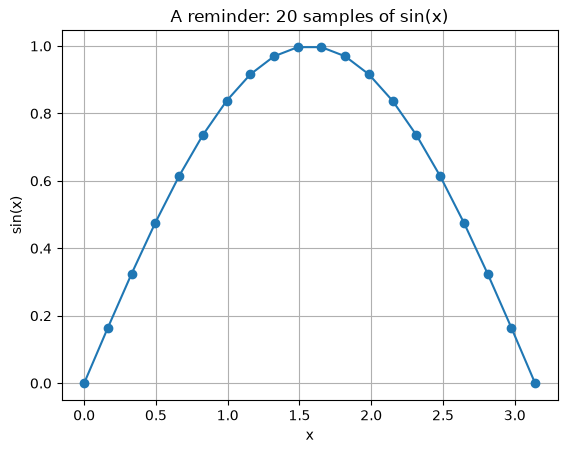

In [4]:
x = np.linspace(0, np.pi, 20)    # 20 evenly spaced points from 0 to pi
u = np.sin(x)                    # sin of every point at once, no loop
h = x[1] - x[0]                  # the spacing between two neighbouring points

trapezoid = np.sum((u[1:] + u[:-1]) / 2) * h   # the trapezoid rule, in one line
print("trapezoid rule:", trapezoid, "   exact value: 2")

plt.figure()
plt.plot(x, u, "o-")
plt.xlabel("x")
plt.ylabel("sin(x)")
plt.title("A reminder: 20 samples of sin(x)")
plt.grid(True)
plt.show()

---
## Part 1 — SciPy

In Session 1 you wrote the numerical methods yourself: Newton–Raphson, finite differences, the
trapezoid rule. This is the best way to understand what they do. For real work, you use **SciPy**:
a library of numerical methods that are well tested, accurate and fast. It is built on top of NumPy.

Today we use three of its tools. Each one is used in the same way: one import, then one function
call.

| Tool | Import | What it does |
|---|---|---|
| Interpolation | `from scipy.interpolate import interp1d` | estimates values **between** known points |
| Integration | `from scipy.integrate import quad` | computes $\int_a^b f(x)\,dx$ |
| Curve fitting | `from scipy.optimize import curve_fit` | finds the parameters of a model that best match data |

A ready-made tool is not a reason to stop checking. **Try it first on a case where you know the
answer.**

### Interpolation

You often know a quantity only at a few points, and you need its value in between. **Interpolation**
builds a function that passes exactly through your points and fills the gaps.

`interp1d(x_samples, y_samples, kind=...)` takes your points and **returns a new function**. You
then call that function like any other, for example on a fine grid.

- `kind="linear"` joins the points with straight lines.
- `kind="cubic"` joins them with smooth cubic curves.

Here the true function is $\sin(x)$, so we can see how good the interpolation is.

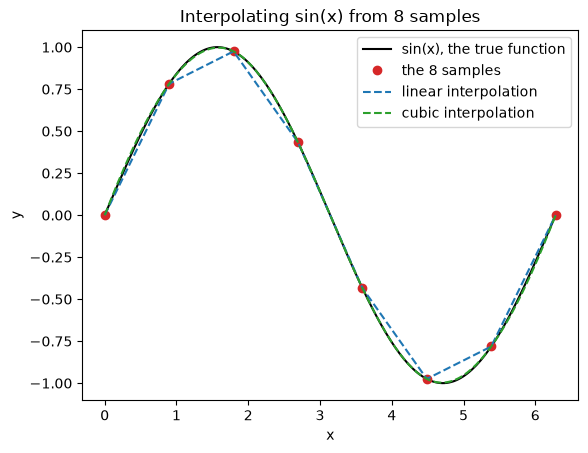

In [6]:
from scipy.interpolate import interp1d

x_samples = np.linspace(0, 2*np.pi, 8)   # we only know sin(x) at these 8 points
y_samples = np.sin(x_samples)

f_linear = interp1d(x_samples, y_samples, kind="linear")   # a function: straight lines between samples
f_cubic = interp1d(x_samples, y_samples, kind="cubic")     # a function: smooth curve through samples

x_fine = np.linspace(0, 2*np.pi, 200)   # a much finer grid, to draw the interpolants

plt.figure()
plt.plot(x_fine, np.sin(x_fine), color="black", label="sin(x), the true function")
plt.plot(x_samples, y_samples, "o", color="tab:red", label="the 8 samples")
plt.plot(x_fine, f_linear(x_fine), "--", color="tab:blue", label="linear interpolation")
plt.plot(x_fine, f_cubic(x_fine), "--", color="tab:green", label="cubic interpolation")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.title("Interpolating sin(x) from 8 samples")
plt.show()

The cubic curve is almost on top of $\sin(x)$. The straight lines cut the corners, especially near
the top and the bottom of the wave.

An interpolant only works **between** your first and your last sample. Outside, it has no
information, and it refuses to guess. The cell below asks for a value outside on purpose. Read the
error message from the bottom, as in Session 1: it tells you exactly what is wrong.

In [7]:
try:
    f_cubic(7.0)          # incorrect on purpose: 7 is beyond the last sample, 2*pi = 6.28
except ValueError as e:
    print("ValueError:", e)

ValueError: A value (7.0) in x_new is above the interpolation range's maximum value (6.283185307179586).


📝 *Note: in SciPy's documentation, `interp1d` is marked as "legacy". It still works, but in newer
code you will also see `np.interp` (linear only) and `scipy.interpolate.CubicSpline`. The idea is
exactly the same.*

**Exercise 1.1 — how accurate is interpolation?**

Take $f(x) = \dfrac{1}{1+x^2}$ on $[-5, 5]$. Pretend that you only know it at 11 evenly spaced
points.

1. Write a Python function `f(x)` for the formula. Build the samples with
   `x_samples = np.linspace(-5, 5, 11)` and `y_samples = f(x_samples)`.
2. Build a linear and a cubic interpolant from these samples with `interp1d`.
3. Make a fine grid `x_fine = np.linspace(-5, 5, 300)`. On **one** figure, draw: the true $f$ as a
   solid line, the two interpolants as dashed lines, and the 11 samples as markers. Add a legend.
4. For each interpolant, print its **largest error** on the fine grid. Which one is more accurate? the cubic one is way better
5. **(bonus)** Do it again with only 6 samples, `np.linspace(-5, 5, 6)`. Both errors become much
   larger. Print the 6 sample points and look at where they are: why do both interpolants fail?

💡 *Hint: `interp1d` returns a function. Call `f_cubic(x_fine)` exactly as you would call
`np.sin(x_fine)`.*

💡 *Hint: the largest error of the linear interpolant is
`np.max(np.abs(f_linear(x_fine) - f(x_fine)))`.*

Linear interpolation max error with 6 samples: 0.49972043924585685
Cubic interpolation max error with 6 samples: 0.4312780452956947


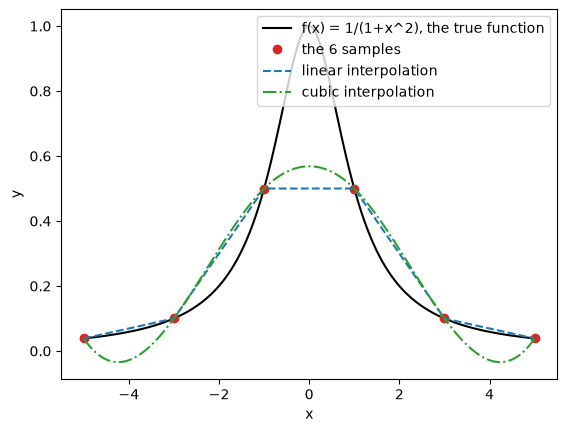

Linear interpolation max error with 11 samples: 0.06736763275871027
Cubic interpolation max error with 11 samples: 0.02197226214659398


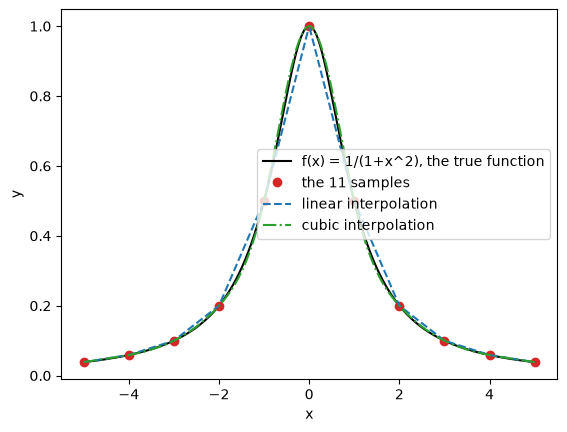

In [10]:
# your code here

f = lambda x: 1/(1+x**2)

def analysis(n):
    x_samples = np.linspace(-5, 5, n)
    y_samples = np.vectorize(f)(x_samples)

    y_linear = interp1d(x_samples, y_samples, kind="linear")
    y_cubic = interp1d(x_samples, y_samples, kind="cubic")

    x_fine = np.linspace(-5, 5, 300)
    y_true = np.vectorize(f)(x_fine)

    plt.figure()
    plt.plot(x_fine, y_true, color="black", label="f(x) = 1/(1+x^2), the true function")
    plt.plot(x_samples, y_samples, "o", color="tab:red", label=f"the {n} samples")
    plt.plot(x_fine, y_linear(x_fine), "--", color="tab:blue", label="linear interpolation")
    plt.plot(x_fine, y_cubic(x_fine), "-.", color="tab:green", label="cubic interpolation")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.legend()

    print(f"Linear interpolation max error with {n} samples:", np.max(np.abs(y_true - y_linear(x_fine))))
    print(f"Cubic interpolation max error with {n} samples:", np.max(np.abs(y_true - y_cubic(x_fine))))

    plt.show()

analysis(6), analysis(11)

plt.show()

### Numerical integration

In Session 1 you wrote the trapezoid rule. You chose the number of points yourself, and you knew how
accurate the result was only because you knew the exact answer.

`quad(f, a, b)` from `scipy.integrate` approximates $\displaystyle\int_a^b f(x)\,dx$ in an
**adaptive** way: it uses more points where the function changes quickly, and stops when it believes
the result is accurate. It returns **two numbers**: the value of the integral, and an estimate of
its error.

Notice the difference: the trapezoid rule works on an **array of values**. You give `quad` the
**function itself**, not its values.

First, check it on a case where you know the answer, $\int_0^{\pi}\sin(x)\,dx = 2$:

In [11]:
from scipy.integrate import quad

value, error_estimate = quad(np.sin, 0, np.pi)   # pass the function itself: np.sin, not np.sin(x)
print("quad value:          ", value, "   exact value: 2")
print("quad error estimate: ", error_estimate)

quad value:           2.0    exact value: 2
quad error estimate:  2.220446049250313e-14


Compare with the warm-up: with 20 points, the trapezoid rule was wrong in the third decimal. `quad`
is correct to about 15 digits, which is as accurate as the computer can be.

Now an integral that has **no formula** with elementary functions. This is exactly when you need a
numerical method.

In [12]:
def g(x):
    return np.sin(x**2)

value, error_estimate = quad(g, 0, 1)   # pass g without parentheses: quad calls it itself
print("quad value:          ", value)
print("quad error estimate: ", error_estimate)

quad value:           0.3102683017233811
quad error estimate:  3.444670123846428e-15


**Exercise 1.2 — the trapezoid rule against `quad`.**

Take $\displaystyle\int_0^2 e^{-x^2}\,dx$. It has no formula with elementary functions either.

1. Write the function, `def gaussian(x): return np.exp(-x**2)`, and compute the integral with
   `quad`. Its error estimate is tiny, so use the `quad` value as the reference.
2. Compute the integral with the trapezoid rule on 10 points. Build `x = np.linspace(0, 2, 10)`,
   `u = gaussian(x)` and `h = x[1] - x[0]`, then use the same one-line formula as in the warm-up,
   `trapezoid = ...`. Print its error, `abs(trapezoid - quad_value)`.
3. Do it again with 1000 points. The grid is about 100 times finer: by roughly what factor does the
   error go down?

💡 *Hint: `quad` returns two numbers. Unpack them on one line:
`quad_value, quad_error = quad(gaussian, 0, 2)`. Pass `gaussian` without parentheses.*

In [16]:
def gaussian(x): return np.exp(-x**2)

value, error_estimate = quad(gaussian, 0, 2)

x = np.linspace(0, 2, 10)
u = gaussian(x)
h = x[1] - x[0]
trapezoid = np.sum((u[1:] + u[:-1]) / 2) * h

abs(trapezoid - value), error_estimate

(np.float64(0.00029900970021567996), 9.793070696178202e-15)

**In practice:** when you have a **formula** for $f$, use `quad`. When you only have **values on a
grid**, from a measurement or a simulation, you cannot use `quad`, because there is no function to
give it: use the trapezoid rule, `np.trapezoid(u, x)`.

### Curve fitting

You have measured data, and a **model** with unknown parameters, for example a straight line
$y = a x + b$. `curve_fit` from `scipy.optimize` finds the values of $a$ and $b$ that make the model
as close as possible to the data. More precisely, it makes the sum of the squared differences between
the model and the data as small as possible: this is a **least-squares** fit.

You always use it in three steps:

1. Write the model as a Python function. **The first argument must be the variable ($x$). The
   parameters come after it.**
2. Call `params, covariance = curve_fit(model, x_data, y_data)`.
3. `params` is an array with the best values of the parameters, in the same order as in your
   function.

`covariance` tells you how uncertain the parameters are. You can ignore it today.

As always, check the tool on a case where you know the answer. The cell below makes fake
"measurements": it takes the exact line $y = 2.5x + 1$ and adds small random errors to it, drawn by
`rng.normal`. Then it fits a line to these points.

fitted a: 2.561859745964089   (true value 2.5)
fitted b: 0.5698126703818245   (true value 1.0)


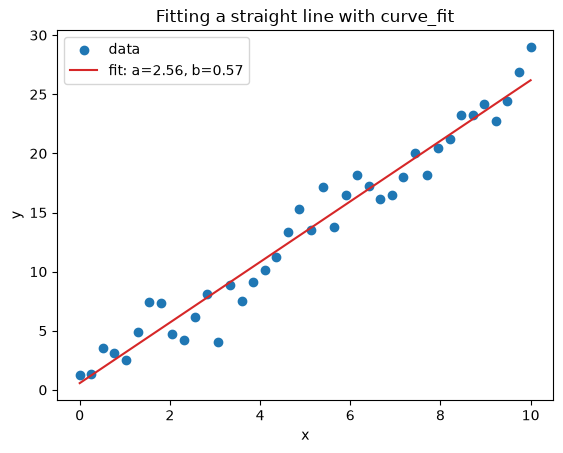

In [17]:
from scipy.optimize import curve_fit

def linear_model(x, a, b):   # first the variable x, then the parameters a and b
    return a*x + b

# fake noisy data around the line y = 2.5 x + 1
rng = np.random.default_rng(0)   # a random number generator; the 0 ("seed") gives the same noise every run
x_data = np.linspace(0, 10, 40)
y_data = 2.5*x_data + 1.0 + rng.normal(scale=2.0, size=x_data.shape)   # noise with standard deviation 2

params, covariance = curve_fit(linear_model, x_data, y_data)
a_fit, b_fit = params   # unpack the array: same order as in linear_model
print("fitted a:", a_fit, "  (true value 2.5)")
print("fitted b:", b_fit, "  (true value 1.0)")

plt.figure()
plt.scatter(x_data, y_data, label="data")
plt.plot(x_data, linear_model(x_data, a_fit, b_fit), color="tab:red",
         label=f"fit: a={a_fit:.2f}, b={b_fit:.2f}")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.title("Fitting a straight line with curve_fit")
plt.show()

The fitted values are not exactly the true ones, because of the random errors. The slope $a$ is very
close to 2.5. The intercept $b$ is further from 1.0: it is the value of the line at $x = 0$, at the
edge of the data, so the errors move it more. Change the seed `0` to another number and run the cell
again: the errors change, and so do the fitted values.

---
## Part 2 — Pandas

In Session 1 every data set was a NumPy array of numbers. Real data usually comes as a **table**:
one row per observation (a day, a sample, a patient), and one column per quantity, each with a name
and a unit. **Pandas** is the standard library for this kind of table. A table is called a
**DataFrame**.

We only use the most common operations: read a file, select a column, filter and sort the rows,
compute simple statistics, and deal with missing values. They are enough for most practical
sessions.

### The data

Daily weather data from **1 June to 15 July 2023**, at three places in France:

- **Station A**: Marne-la-Vallée, home of the school;
- **Station B**: La Rochelle, on the Atlantic coast;
- **Station C**: Chamonix, in the Alps.

There is one row per station per day, so $3 \times 45 = 135$ rows. The data comes from
[Open-Meteo](https://open-meteo.com). The values come from a weather model corrected with real
observations (*reanalysis* data), not from a single thermometer. A few values were removed on
purpose, to imitate the sensor failures you see in any real data set.

These weeks were unusually warm: June 2023 was the second-hottest June in France since 1900,
according to Météo-France. At our three stations, the period was 1.5 to 3 °C warmer than the
1991–2020 average for the same dates.

| Column | Meaning | Unit |
|---|---|---|
| `date` | the day | — |
| `station` | which station | — |
| `temperature_C` | air temperature at 2 m above the ground, **mean** of the day | °C |
| `humidity_pct` | relative humidity, **mean** of the day | % |
| `pressure_hPa` | air pressure at the height of the station, **mean** of the day | hPa |
| `wind_kmh` | wind speed at 10 m above the ground, **maximum** of the day | km/h |

1 hPa (hectopascal) = 100 Pa. The normal air pressure at sea level is about 1013 hPa.

⚠️ Look at the last line: `wind_kmh` is the **strongest** wind of each day, not its average. Always
check what each column means before you interpret it.

### Reading a data file

`pd.read_csv` reads a CSV file into a DataFrame. `parse_dates=["date"]` tells Pandas that the
column `date` contains dates, not just text. `.head()` shows the first 5 rows: it is the quickest way
to check that the file loaded correctly.

If you get `FileNotFoundError`, the file is not in the same folder as this notebook.

In [18]:
df = pd.read_csv("weather_bootcamp.csv", parse_dates=["date"])   # read the file into a DataFrame called df
df.head()                                                        # the first 5 rows

,date,station,temperature_C,humidity_pct,pressure_hPa,wind_kmh
0,2023-06-01,Station A,20.0,59.0,1006.6,20.8
1,2023-06-02,Station A,15.1,66.0,1006.9,21.4
2,2023-06-03,Station A,17.4,59.0,1005.5,18.3
3,2023-06-04,Station A,19.4,49.0,1005.9,18.7
4,2023-06-05,Station A,19.6,48.0,1006.1,19.8


Every time you load a file, check the **names** of the columns and the **size** of the table.
`.shape` works exactly as for a NumPy array.

In [19]:
print(df.columns.tolist())   # the column names
print(df.shape)              # (number of rows, number of columns)

['date', 'station', 'temperature_C', 'humidity_pct', 'pressure_hPa', 'wind_kmh']
(135, 6)


### Selecting a column

`df["temperature_C"]` gives one column. You can use it much like a NumPy array.

In [20]:
temperatures = df["temperature_C"]   # one column
temperatures.head()                  # its first 5 values

0    20.0
1    15.1
2    17.4
3    19.4
4    19.6
Name: temperature_C, dtype: float64

The name must be written **exactly** as in the table: same capital letters, same underscores.
Otherwise you get a `KeyError`, which tells you the name that was not found:

In [21]:
try:
    df["Temperature"]         # incorrect on purpose: the column is called "temperature_C"
except KeyError as e:
    print("KeyError:", e)

KeyError: 'Temperature'


### Simple statistics on a column

A column has built-in methods: `.mean()`, `.std()`, `.min()`, `.max()`. There is no loop to
write. Missing values are skipped automatically.

In [22]:
print("mean:", df["temperature_C"].mean())
print("standard deviation:", df["temperature_C"].std())
print("min and max:", df["temperature_C"].min(), df["temperature_C"].max())

mean: 19.466165413533833
standard deviation: 2.730131732254211
min and max: 13.4 26.1


You can also make a **new column** from an existing one, with ordinary arithmetic. As with NumPy,
the operation is done on every row at once.

In [23]:
df["temperature_F"] = df["temperature_C"] * 9/5 + 32   # a new column, in degrees Fahrenheit
df.head()

,date,station,temperature_C,humidity_pct,pressure_hPa,wind_kmh,temperature_F
0,2023-06-01,Station A,20.0,59.0,1006.6,20.8,68.00
1,2023-06-02,Station A,15.1,66.0,1006.9,21.4,59.18
2,2023-06-03,Station A,17.4,59.0,1005.5,18.3,63.32
3,2023-06-04,Station A,19.4,49.0,1005.9,18.7,66.92
4,2023-06-05,Station A,19.6,48.0,1006.1,19.8,67.28


### Filtering rows with a condition

A comparison on a column gives one `True` or `False` **per row**. Put it inside `df[...]` to keep
**only the rows where it is `True`**:

In [26]:
df_warm = df[df["temperature_C"] > 20]   # keep only the days warmer than 20 °C
print(len(df_warm), "rows out of", len(df))
df_warm.head()

60 rows out of 135


,date,station,temperature_C,humidity_pct,pressure_hPa,wind_kmh,temperature_F
6,2023-06-07,Station A,20.9,56.0,1004.6,17.9,69.62
7,2023-06-08,Station A,20.9,60.0,1001.9,15.2,69.62
8,2023-06-09,Station A,23.1,53.0,998.0,17.0,73.58
9,2023-06-10,Station A,22.8,67.0,999.6,11.5,73.04
10,2023-06-11,Station A,21.0,84.0,1001.9,14.2,69.80


The same idea selects **one station**. You get a smaller table, and you can then compute on its
columns as before. You will use this a lot.

In [27]:
station_c = df[df["station"] == "Station C"]   # only the rows of Station C
print(len(station_c), "rows")
print("mean temperature at Station C:", station_c["temperature_C"].mean())

45 rows
mean temperature at Station C: 16.98863636363636


To combine two conditions, use `&` for "and". Put **each condition in parentheses**:

```python
df[(df["temperature_C"] > 20) & (df["wind_kmh"] < 10)]   # warm AND calm
```

The Python word `and` does **not** work here. The cell below uses it on purpose:

In [28]:
try:
    df[(df["temperature_C"] > 20) and (df["wind_kmh"] < 10)]   # incorrect on purpose: 'and' instead of '&'
except ValueError as e:
    print("ValueError:", e)

ValueError: The truth value of a Series is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.all().


Remember this message: **"The truth value of a Series is ambiguous"** almost always means that you
wrote `and` instead of `&`.

**Exercise 2.1 — combining two conditions.** How many days at Station B had a humidity above 60 %?

1. Write the condition "the station is Station B": `df["station"] == "Station B"`.
2. Write the condition "the humidity is above 60".
3. Combine them with `&`, keep the matching rows, and count them with `len(...)`.

💡 *Hint: put each condition in parentheses. Write the text exactly as it is in the table, in
quotes, with the capital letter and the space: `"Station B"`.*

In [31]:
len(df[(df["station"] == "Station B") & (df["humidity_pct"]>60)])

41

**Break — 15 minutes.**

Before you leave, run *Kernel → Restart Kernel and Run All Cells* and check that your notebook still
runs correctly up to here.

### Sorting

`df.sort_values("column")` sorts the rows by that column, from the smallest value to the largest.
Add `ascending=False` to go from the largest to the smallest.

In [32]:
df.sort_values("temperature_C", ascending=False).head()   # the 5 hottest days

,date,station,temperature_C,humidity_pct,pressure_hPa,wind_kmh,temperature_F
37,2023-07-08,Station A,26.1,54.0,1003.6,14.3,78.98
40,2023-07-11,Station A,24.4,52.0,1002.1,19.6,75.92
24,2023-06-25,Station A,24.1,62.0,1004.9,24.9,75.38
130,2023-07-11,Station C,23.6,53.0,905.6,11.5,74.48
68,2023-06-24,Station B,23.4,64.0,1019.9,16.9,74.12


### Missing values

⚠️ Real data sets almost always have gaps: sensors fail, and values get lost. Pandas shows a missing
value as `NaN` ("not a number"). `df.isna().sum()` counts the missing values in each column.

In [33]:
print(df.isna().sum())   # number of missing values in each column

date             0
station          0
temperature_C    2
humidity_pct     3
pressure_hPa     0
wind_kmh         4
temperature_F    2
dtype: int64


Statistics such as `.mean()` skip the missing values. But some tools stop with an error when they
meet one: you will see an example, and how to fix it, in Part 3.

**Exercise 2.2 — pressure and altitude.** Station A (Marne-la-Vallée) is at 102 m of altitude, and
Station C (Chamonix) is at 1034 m.

1. Compute the mean pressure, `pressure_hPa`, at Station A and at Station C.
2. Which one is lower, and by how much? Can you explain why?
3. **(bonus)** Near the ground, the air pressure goes down by about 12 hPa for every 100 m you go up.
   Is the difference about what you expect from the two altitudes? Marginalement oui.

💡 *Hint: select one station as in the Station C example above,
`station_a = df[df["station"] == "Station A"]`, then use `station_a["pressure_hPa"].mean()`.*

In [39]:
PA = df[(df["station"] == "Station A")].get("pressure_hPa").mean()
PC = df[(df["station"] == "Station C")].get("pressure_hPa").mean()
PA, PC, (PA - PC) / (1034-102) *100

(np.float64(1003.951111111111),
 np.float64(902.0422222222222),
 np.float64(10.934430138292788))

### A quick plot

The columns go directly into the usual `plt` functions, as in Session 1.

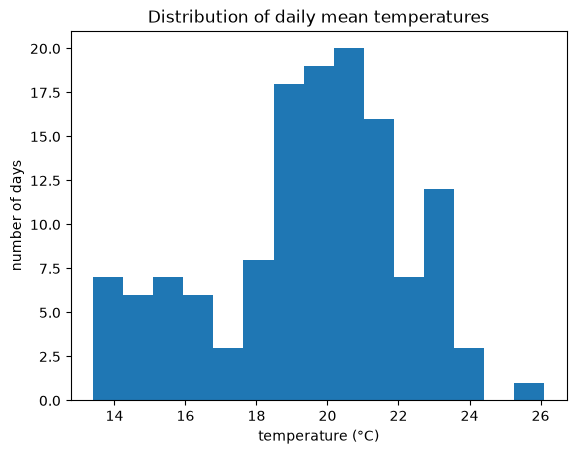

In [40]:
plt.figure()
plt.hist(df["temperature_C"], bins=15)   # how many days fall in each temperature range
plt.title("Distribution of daily mean temperatures")
plt.xlabel("temperature (°C)")
plt.ylabel("number of days")
plt.show()

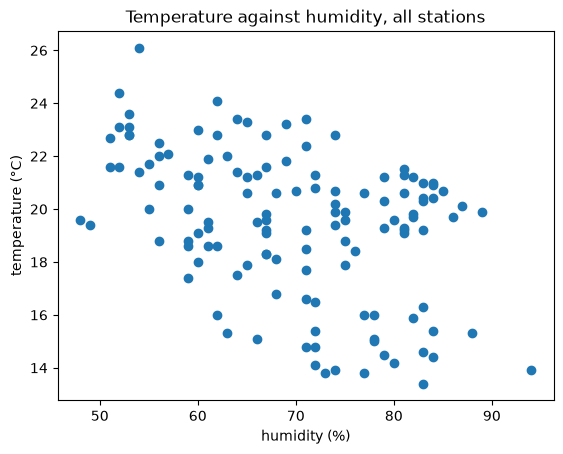

In [41]:
plt.figure()
plt.scatter(df["humidity_pct"], df["temperature_C"])   # one point per day and per station
plt.xlabel("humidity (%)")
plt.ylabel("temperature (°C)")
plt.title("Temperature against humidity, all stations")
plt.show()

---
## Part 3 — A guided mini-project

You now use everything on the full data set, in the order that a real small project follows:

1. **clean** the data (Exercise 3.1);
2. **look** at it (Exercise 3.2);
3. **model** it (Exercise 3.3);
4. **answer questions** with numbers (Exercise 3.4).

Each exercise uses `df_clean`, the cleaned table of Exercise 3.1, so do them in order.

Why clean first? Try to fit a straight line to the data as it is. `curve_fit` stops immediately,
because some values are missing:

In [42]:
try:
    curve_fit(linear_model, df["humidity_pct"], df["temperature_C"])   # fails on purpose: the data has NaN
except ValueError as e:
    print("ValueError:", e)

ValueError: array must not contain infs or NaNs


**Exercise 3.1 — remove the missing values.** The simplest way to deal with missing values is to
**remove the rows** that contain one. Pandas has a method for this: `df.dropna()` ("drop NA", where
NA means "not available", that is, missing). It gives a **new** table without these rows, and leaves
`df` unchanged.

1. Print the number of rows, `len(df)`, and the number of missing values in each column.
2. Make the cleaned table: `df_clean = df.dropna()`.
3. Print the number of rows and the number of missing values of `df_clean`. How many rows did you
   lose? Is that a problem here?

From now on, use `df_clean` in every exercise of Part 3. `df` stays as it was, with its missing
values, so every cell above still gives the same result if you run it again.

📝 *Note: another way is to fill each gap from the days around it, as with interpolation in Part 1.
Removing the rows is simpler, and every value that is left comes from the data set: none of them is
an estimate.*

In [44]:
df_clean = df.dropna()

len(df_clean), len(df)

(126, 135)

**Exercise 3.2 — compare the stations on one figure.** Draw the temperature against the date, with
**one line per station**, on one figure.

1. Write a loop over the stations: `for station in ["Station A", "Station B", "Station C"]:`
2. Inside the loop, select the rows of that station, `station_df = df_clean[df_clean["station"] == station]`,
   and draw `station_df["temperature_C"]` against `station_df["date"]`, with `label=station`.
3. After the loop, add a title, axis labels with units, and a legend. The dates are long, so turn
   them with `plt.xticks(rotation=45)`.
4. Look at the figure. Which station is the coldest? Which one changes the least from day to day?
   Can you think of a physical reason for each? Station C is the coldest, station B changes least from day to day. Chamonix is cold coz high up. The temperature of station B = La Rochelle set by the ocean = doesn't move much.

💡 *Hint: call `plt.figure()` once **before** the loop, and `plt.show()` once **after** it. Otherwise
you get three separate figures.*

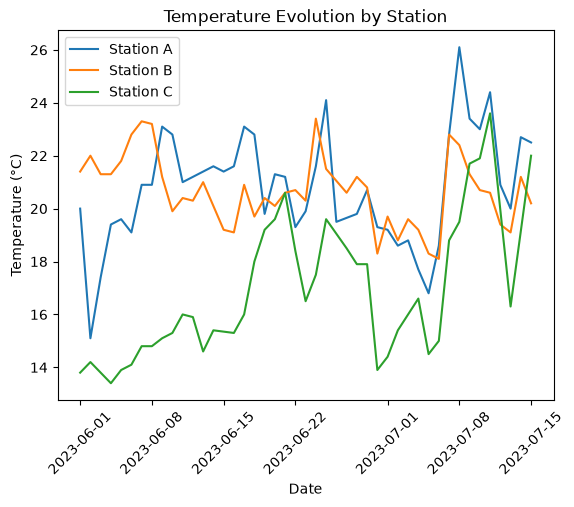

In [47]:
for station in ["Station A", "Station B", "Station C"]:
    df_station = df_clean[df_clean["station"] == station]
    plt.plot(df_station["date"], df_station["temperature_C"], label=station)
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.xticks(rotation=45)
plt.title("Temperature Evolution by Station")
plt.legend()
plt.show()

**Exercise 3.3 — fit a model.** Are humid days cooler? Fit a straight line $T = a \cdot H + b$, where
$T$ is `temperature_C` and $H$ is `humidity_pct`.

1. Select the rows of **Station C** only, from `df_clean`.
2. Fit the model with `curve_fit`, using the function `linear_model` from Part 1. Print `a` and `b`.
   What does the sign of `a` tell you? T is decreasing with H
3. On one figure, draw the data as points and the fitted line. Add axis labels, a legend and a
   title.
4. Are the points close to the line, or very spread around it? Would you use this line to
   **predict** the temperature of one particular day?
5. **(bonus)** Do the same for Station A, and compare the two slopes.

💡 *Hint: `linear_model` is defined in Part 1. If you restarted the kernel, run that cell again.*

💡 *Hint: to draw the line, make a grid of humidity values with
`np.linspace(station_c["humidity_pct"].min(), station_c["humidity_pct"].max(), 100)` and evaluate
`linear_model` on it.*

In [69]:
def T_by_G(station, G):
    df_station = df_clean[df_clean["station"] == station]

    params, covariance = curve_fit(linear_model, df_station[G], df_station["temperature_C"])
    a_fit, b_fit = params
    print(station + ": a = " + str(a_fit) + ", b = " + str(b_fit))

    MAE = np.mean(np.abs(df_station["temperature_C"] - linear_model(df_station[G], a_fit, b_fit)))
    print(station + ": mean absolute error = " + str(MAE))

    plt.plot(df_station[G], df_station["temperature_C"], "o", label="data")
    plt.plot(df_station[G], linear_model(df_station[G], a_fit, b_fit), label="fit")
    plt.xlabel(G)
    plt.ylabel("Temperature (°C)")
    plt.title(f"Linear Fit for {station}")
    plt.legend()
    #plt.show()

    return a_fit, b_fit, MAE

MAE = {}
"""
for station in ["Station A", "Station B", "Station C"]:
    for G in ["humidity_pct", "wind_kmh", "pressure_hPa"]:
        _, _, mae = T_by_G(station, G)
        MAE[(station, G)] = mae
"""

def linear_n_model(X, T0, aH, aW, aP):
    return T0 + aH * X[:, 0] + aW * X[:, 1] + aP * X[:, 2]

def T_by_all(station):
    df_station = df_clean[df_clean["station"] == station]

    X = df_station[["humidity_pct", "wind_kmh", "pressure_hPa"]].values

    params, covariance = curve_fit(linear_n_model, X, df_station["temperature_C"].values)
    T0, aH, aW, aP = params
    print(station + ": T0 = " + str(T0) + ", aH = " + str(aH) + ", aW = " + str(aW) + ", aP = " + str(aP))

    MAE = np.mean(np.abs(df_station["temperature_C"] - linear_n_model(X, T0, aH, aW, aP)))
    print(station + ": mean absolute error = " + str(MAE))

    return T0, aH, aW, aP, MAE

X = ["humidity_pct", "wind_kmh", "pressure_hPa"]

for station in ["Station A", "Station B", "Station C"]:
    T_by_all(station)

print(MAE)

Station A: T0 = 245.0167586706621, aH = -0.054772387079372785, aW = -0.13799055042085237, aP = -0.21747922203830417
Station A: mean absolute error = 1.5438173890827482
Station B: T0 = 155.73585005117306, aH = -0.06904699170906314, aW = -0.01569577738373912, aP = -0.12780484595867195
Station B: mean absolute error = 0.8370848003205171
Station C: T0 = -239.70820623812625, aH = -0.10429369098617336, aW = 0.4659477043935506, aP = 0.2890129380874452
Station C: mean absolute error = 1.256777287479893
{}


**Exercise 3.4 — answer questions with numbers.** For each station, print **one line** with three
numbers: its mean temperature, its mean `wind_kmh`, and its number of days with a mean temperature
above 22 °C. (A daily **mean** of 22 °C is a hot day: the afternoon is several degrees warmer.)

1. Write a loop over the three stations, as in Exercise 3.2, and select the rows of each station.
2. Inside the loop, compute the three numbers and print them on one line.
3. Which station is the coldest? The windiest? Which one had the most hot days?
4. **(bonus)** In a new Markdown cell, write three sentences that compare the three places, as you
   would in a lab report. Use your numbers.

💡 *Hint: to count the hot days, filter and count the rows:
`len(station_df[station_df["temperature_C"] > 22])`.*

💡 *Hint: `round(x, 1)` keeps one decimal, so that the line is easy to read.*

In [53]:
for station in ["Station A", "Station B", "Station C"]:
    df_station = df_clean[df_clean["station"] == station]
    mean_temp = df_station["temperature_C"].mean()
    mean_wind = df_station["wind_kmh"].mean()
    n_hot_days = len(df_station[df_station["temperature_C"] > 22])
    print(f"{station}: mean temperature = {mean_temp:.2f} °C, mean wind speed = {mean_wind:.2f} km/h, number of hot days (>22 °C) = {n_hot_days}")

Station A: mean temperature = 20.76 °C, mean wind speed = 18.00 km/h, number of hot days (>22 °C) = 12
Station B: mean temperature = 20.65 °C, mean wind speed = 21.35 km/h, number of hot days (>22 °C) = 6
Station C: mean temperature = 16.82 °C, mean wind speed = 7.31 km/h, number of hot days (>22 °C) = 1


---
## Going further — if you have finished early

### How thick is the atmosphere?

In Exercise 2.2 you saw that the air pressure decreases with altitude. In an atmosphere at constant
temperature $T$, it decreases **exponentially**:

$$P(z) = P_0\, e^{-z/H}, \qquad H = \frac{R\,T}{M\,g},$$

where $z$ is the altitude, $P_0$ is the pressure at sea level, $R = 8.314$ J/(mol·K), $M = 0.029$
kg/mol is the molar mass of air and $g = 9.81$ m/s². $H$ is called the **scale height**: going up by
$H$ divides the pressure by $e$. At 20 °C, $H \approx 8.6$ km.

The cell below computes the mean pressure of each station, and fits this model to the three points.
It uses `df`: the column `pressure_hPa` has no missing values, so it does not need the cleaning of
Part 3.

mean pressures: [1003.95111111 1014.57333333  902.04222222]
P0 = 1016 hPa   (pressure at sea level)
H  = 8.7 km  (theory at 20 °C: 8.6 km)


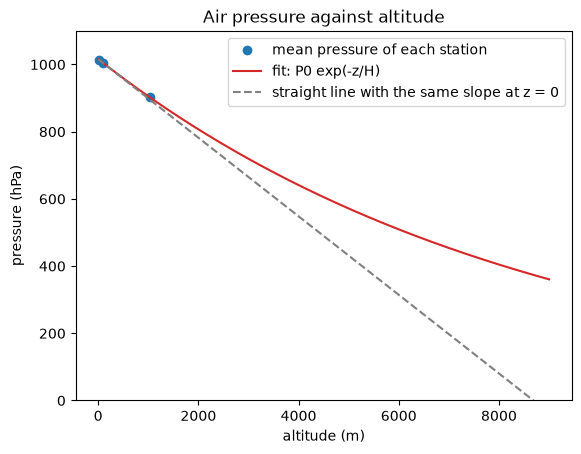

In [54]:
stations = ["Station A", "Station B", "Station C"]
altitudes = np.array([102.0, 14.0, 1034.0])   # in metres, in the same order as the list above

pressures = np.zeros(3)                        # make room for the three mean pressures
for k in range(3):
    station_df = df[df["station"] == stations[k]]
    pressures[k] = station_df["pressure_hPa"].mean()
print("mean pressures:", pressures)

def barometric(z, P0, H):
    return P0 * np.exp(-z / H)

params, covariance = curve_fit(barometric, altitudes, pressures, p0=[1013, 8000])
P0_fit, H_fit = params
print(f"P0 = {P0_fit:.0f} hPa   (pressure at sea level)")
print(f"H  = {H_fit / 1000:.1f} km  (theory at 20 °C: 8.6 km)")

z_grid = np.linspace(0, 9000, 200)   # up to 9 km, about the height of Mount Everest
plt.figure()
plt.plot(altitudes, pressures, "o", label="mean pressure of each station")
plt.plot(z_grid, barometric(z_grid, P0_fit, H_fit), color="tab:red", label="fit: P0 exp(-z/H)")
plt.plot(z_grid, P0_fit * (1 - z_grid / H_fit), "--", color="gray",
         label="straight line with the same slope at z = 0")
plt.ylim(0, 1100)
plt.xlabel("altitude (m)")
plt.ylabel("pressure (hPa)")
plt.legend()
plt.title("Air pressure against altitude")
plt.show()

The fitted scale height is within about 2 % of the theory, and $P_0$ is close to the usual sea-level
pressure, 1013 hPa.

Look at the bottom left of the figure. **Near the ground, the exponential is almost a straight
line**: below about 1 km, $z/H$ is small and $e^{-z/H} \approx 1 - z/H$. The slope of this straight
line is $P_0/H \approx 11.7$ hPa per 100 m: this is the rule "12 hPa per 100 m" of Exercise 2.2. The
two only separate higher up. The straight line would reach zero pressure at $z = H$, about 9 km,
which is impossible; the exponential never reaches zero.

So be careful with what the fit shows. Our three stations are all below 1.1 km, where the two
curves are the same: they cannot prove that the pressure decreases exponentially. They measure the
slope, and the fit turns it into $H$ **by assuming** that the exponential model is right. Above
1.1 km, the red curve is the prediction of the model, not data.

Here `curve_fit` needs a **starting guess**, `p0=[1013, 8000]`: a rough idea of the answer is
enough. Remove it and run the cell again: `curve_fit` starts from $P_0 = 1$ hPa and $H = 1$ m, far
from the answer, and ends with a meaningless result and a warning.

Try it: use the fitted model to estimate the pressure at the top of Mont Blanc (4806 m) and at the
top of Mount Everest (8849 m). Compare with two reference values:

- Mont Blanc: the standard model of the atmosphere, which takes into account that the air gets colder
  as you go up, gives about 555 hPa;
- Everest: the first measurement on the summit, in 1981, gave 337 hPa.

Are your estimates too high or too low? Why?

In [55]:
P = lambda z: barometric(z, P0_fit, H_fit)

P(4806), P(8849)

(np.float64(584.3496265019795), np.float64(366.9292923717862))

---
## Where you are now

You can now estimate values between known points, compute an integral with `quad`, and fit a model
to data with `curve_fit`. You can read a data file with Pandas, select a column, filter and sort the
rows, compute simple statistics, and find and remove missing values. With Session 1, this is enough
to start the practical sessions of your first-year courses without losing time on the tool.

**Good habits with data.**

- Look at the data before you compute anything: `.head()`, `.columns`, `.shape`.
- Check what each column means and its unit. A daily maximum is not a daily mean.
- Count the missing values, and decide what to do with them.
- When the data mixes several places or groups, check your statistics for each one separately.
- Check every tool on a case where you know the answer. A fit gives a trend, not a proof: always draw
  the data together with the fitted model.
- Put a title, axis labels **with units** and a legend on every figure.
- Before you submit a notebook: *Kernel → Restart Kernel and Run All Cells*.

**Where to find help.**

- [10 minutes to Pandas](https://pandas.pydata.org/docs/user_guide/10min.html): a short tour of
  Pandas.
- [The SciPy user guide](https://docs.scipy.org/doc/scipy/tutorial/index.html): every part of SciPy,
  with examples.
- [The Matplotlib gallery](https://matplotlib.org/stable/gallery/index.html): find the figure you
  want, and copy the code under it.

In [70]:
print(df[df.isna().any(axis=1)])

df_predicted = df.copy()  # make a copy of the original DataFrame to fill in missing values
for station in ["Station A", "Station B", "Station C"]:
    T0, aH, aW, aP, MAE = T_by_all(station)
    df_predicted[df_predicted["temperature_C"].isna() & df_predicted["station"] == station] = T0 + aH * df_predicted[df_predicted["temperature_C"].isna() & df_predicted["station"] == station]["humidity_pct"] + aW * df_predicted[df_predicted["temperature_C"].isna() & df_predicted["station"] == station]["wind_kmh"] + aP * df_predicted[df_predicted["temperature_C"].isna() & df_predicted["station"] == station]["pressure_hPa"]

          date    station  temperature_C  humidity_pct  pressure_hPa  \
11  2023-06-12  Station A            NaN          79.0        1001.9   
12  2023-06-13  Station A           22.1          57.0         998.8   
26  2023-06-27  Station A           18.6          61.0        1010.4   
58  2023-06-14  Station B           21.0           NaN        1012.2   
70  2023-06-26  Station B           19.9          75.0        1021.5   
104 2023-06-15  Station C            NaN          62.0         901.1   
115 2023-06-26  Station C           19.5           NaN         906.1   
131 2023-07-12  Station C           19.3          81.0         903.3   
133 2023-07-14  Station C           19.0           NaN         902.7   

     wind_kmh  temperature_F  
11       12.6            NaN  
12        NaN          71.78  
26        NaN          65.48  
58       26.2          69.80  
70        NaN          67.82  
104       8.4            NaN  
115       7.0          67.10  
131       NaN          66.74  


C:\Users\joaqu\AppData\Local\Temp\ipykernel_22352\2167993831.py:6: Pandas4Warning: 'and' operations between boolean dtype and str are deprecated and will raise in a future version. Explicitly cast the strings to a boolean dtype before operating instead.
  df_predicted[df_predicted["temperature_C"].isna() & df_predicted["station"] == station] = T0 + aH * df_predicted[df_predicted["temperature_C"].isna() & df_predicted["station"] == station]["humidity_pct"] + aW * df_predicted[df_predicted["temperature_C"].isna() & df_predicted["station"] == station]["wind_kmh"] + aP * df_predicted[df_predicted["temperature_C"].isna() & df_predicted["station"] == station]["pressure_hPa"]
C:\Users\joaqu\AppData\Local\Temp\ipykernel_22352\2167993831.py:6: Pandas4Warning: 'and' operations between boolean dtype and str are deprecated and will raise in a future version. Explicitly cast the strings to a boolean dtype before operating instead.
  df_predicted[df_predicted["temperature_C"].isna() & df_predicted["

ValueError: Must have equal len keys and value when setting with an iterable